# APID 14 exploration

APID 14 is the 5th most common APID (1 738 packets) and nearly all of them are 24 bytes long. In APID 2 and APID 0 we
saw `10 01 01` / `10 01 07` packets, PUS telecommand verification reports; here they are the whole APID. Questions:

1. What exactly is in a report, and how do the reports relate to each other?
2. What does the telecommand log tell about the ground contacts and the dumps?
3. Anything LYRA, or the position of the Sun?

In [1]:
from collections import Counter, defaultdict
from datetime import UTC, datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from cadu import iter_packets, packet_apid

In [2]:
CADU_DIR = Path("cadus")
APID = 14

# A report is 24 bytes: 6 byte primary header, PUS secondary header (version, service 1, subtype 1 or 7), the marker
# `00 01`, a 4 byte tick counter (seconds) with a 2 byte fraction, a `00`, the 4 byte request id of the telecommand and
# a CRC-16.
REPORT_LEN = 24
SERVICE_OFFSET = 7
MARKER_OFFSET = 9
TIME_OFFSET = 11
FRACTION_OFFSET = 15
REQUEST_OFFSET = 18
CRC_LEN = 2
ACCEPTED = 1
COMPLETED = 7

TEXT_HEADER = bytes.fromhex("100889")  # APID 18 text packets: used to find the time span of a dump
MAX_TICK_SPREAD = 10_000_000
GPS_EPOCH = datetime(1980, 1, 6, tzinfo=UTC)
GPS_MINUS_TICK = 1_209_613_891  # GPS seconds minus tick, from APID_0.ipynb / APID_18.ipynb
BURST_GAP = 30  # seconds without a command that end a burst

## 1. Load

One pass keeps the APID 14 packets and, to see where in a dump the commands are, the ticks of the APID 18 packets.

In [3]:
packets: list[tuple[str, int, bytes]] = []  # (file name, vcid, packet)
text_ticks: dict[str, list[int]] = defaultdict(list)
for path in sorted(CADU_DIR.glob("*.cadu")):
    for vcid, packet in iter_packets(path):
        apid = packet_apid(packet)
        if apid == APID:
            packets.append((path.name, vcid, packet))
        elif apid == 18 and packet[6:9] == TEXT_HEADER:
            text_ticks[path.name].append(int.from_bytes(packet[11:15]))
    print(f"processed {path.name}")

print(f"{len(packets)} packets with APID {APID}")
print("per file:", dict(Counter(name for name, _, _ in packets)))
print("per virtual channel:", dict(Counter(vcid for _, vcid, _ in packets)))

processed proba2_dump(1).cadu
processed proba2_dump(10).cadu
processed proba2_dump(11).cadu
processed proba2_dump(12).cadu
processed proba2_dump(2).cadu
processed proba2_dump(3).cadu
processed proba2_dump(4).cadu
processed proba2_dump(5).cadu
processed proba2_dump(6).cadu
processed proba2_dump(7).cadu
processed proba2_dump(8).cadu
processed proba2_dump(9).cadu
processed proba2_dump.cadu
processed proba2_dump_aug_12_eclipse.cadu
1738 packets with APID 14
per file: {'proba2_dump(1).cadu': 233, 'proba2_dump(10).cadu': 42, 'proba2_dump(11).cadu': 138, 'proba2_dump(12).cadu': 248, 'proba2_dump(2).cadu': 118, 'proba2_dump(3).cadu': 160, 'proba2_dump(4).cadu': 98, 'proba2_dump(5).cadu': 79, 'proba2_dump(6).cadu': 260, 'proba2_dump(7).cadu': 110, 'proba2_dump(8).cadu': 190, 'proba2_dump(9).cadu': 2, 'proba2_dump.cadu': 60}
per virtual channel: {1: 1541, 2: 197}


## 2. Packet types

In [4]:
print("lengths:", Counter(len(packet) for _, _, packet in packets).most_common(5))
print("secondary headers:", Counter(packet[6:9].hex() for _, _, packet in packets).most_common(6))
print("sequence flags:", Counter(packet[2] >> 6 for _, _, packet in packets))


def crc16(data: bytes) -> int:
    """CRC-16/CCITT-FALSE."""
    crc = 0xFFFF
    for byte in data:
        crc ^= byte << 8
        for _ in range(8):
            crc = ((crc << 1) ^ 0x1021) & 0xFFFF if crc & 0x8000 else (crc << 1) & 0xFFFF
    return crc

lengths: [(24, 1735), (61, 1), (721, 1), (75, 1)]
secondary headers: [('100101', 868), ('100107', 866), ('100319', 1), ('10a9e9', 1), ('0fdc65', 1), ('105507', 1)]
sequence flags: Counter({3: 1736, 0: 1, 1: 1})


1 735 of the packets are 24 bytes with a `10 01 01` or `10 01 07` secondary header: PUS service 1 (telecommand
verification), subtype 1 (acceptance) and subtype 7 (completion of execution). The few others (61, 75 and 721 bytes) are
debris from lost frames and bit errors (the 61 byte one is an APID 2 housekeeping report with a corrupted APID, as in
`APID_0.ipynb`). Keep the 24 byte reports with a valid marker and CRC.

In [5]:
reports = [
    (name, vcid, packet)
    for name, vcid, packet in packets
    if len(packet) == REPORT_LEN
    and packet[SERVICE_OFFSET] == 1
    and packet[SERVICE_OFFSET + 1] in (ACCEPTED, COMPLETED)
    and packet[MARKER_OFFSET : MARKER_OFFSET + 2] == b"\x00\x01"
]
crc_ok = np.array([crc16(packet[:-CRC_LEN]) == int.from_bytes(packet[-CRC_LEN:]) for _, _, packet in reports])
print(f"{len(reports)} reports, CRC-16 ok in {crc_ok.mean():.1%}")
reports = [report for report, ok in zip(reports, crc_ok, strict=True) if ok]
print("subtypes:", Counter(packet[SERVICE_OFFSET + 1] for _, _, packet in reports))
print("byte 17 (after the time):", Counter(packet[17] for _, _, packet in reports))

1732 reports, CRC-16 ok in 99.9%
subtypes: Counter({1: 866, 7: 865})
byte 17 (after the time): Counter({0: 1731})


## 3. The request id

The 4 bytes at 18 are the *request id* of the telecommand being reported on: the packet id and the packet sequence
control of the telecommand packet, the two first words of its CCSDS header.

In [6]:
def request_id(packet: bytes) -> tuple[int, int, int, int, int, int]:
    """(version, type, secondary header flag, APID, sequence flags, sequence count) of the telecommand."""
    packet_id = int.from_bytes(packet[REQUEST_OFFSET : REQUEST_OFFSET + 2])
    sequence = int.from_bytes(packet[REQUEST_OFFSET + 2 : REQUEST_OFFSET + 4])
    return (
        packet_id >> 13,
        (packet_id >> 12) & 1,
        (packet_id >> 11) & 1,
        packet_id & 0x7FF,
        sequence >> 14,
        sequence & 0x3FFF,
    )


ids = Counter(request_id(packet)[:5] for _, _, packet in reports)
print("(version, type, secondary header flag, APID, sequence flags) of the telecommands:", dict(ids))

(version, type, secondary header flag, APID, sequence flags) of the telecommands: {(0, 1, 1, 14, 3): 1731}


Every report is about a telecommand packet of type 1 (a telecommand), with a secondary header, APID 14 and unsegmented
(flags 3). So the commands are sent to APID 14, and APID 14 in the downlink is the replies. The count is the 14 bit
sequence count of the commands.

## 4. Acceptance and completion

Each command should give a subtype 1 report (accepted) and a subtype 7 report (execution completed). The same report
can reach the ground on virtual channel 1 (stored) and 2 (real time), so key them by file, count and subtype.

In [7]:
def when(packet: bytes) -> float:
    whole = int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4])
    return whole + int.from_bytes(packet[FRACTION_OFFSET : FRACTION_OFFSET + 2]) / 65536


commands: dict[tuple[str, int], dict[int, float]] = defaultdict(dict)  # (file, count) -> subtype -> time
duplicates = 0
for name, _, packet in reports:
    key = name, request_id(packet)[5]
    subtype = packet[SERVICE_OFFSET + 1]
    duplicates += subtype in commands[key]
    commands[key][subtype] = when(packet)
print(f"{len(commands)} commands, {duplicates} reports seen twice (on both virtual channels)")
print("subtypes per command:", Counter(tuple(sorted(item)) for item in commands.values()))

latency = np.array([item[COMPLETED] - item[ACCEPTED] for item in commands.values() if len(item) == 2])
print(
    f"completion minus acceptance: median {np.median(latency) * 1000:.2f} ms, "
    f"5 % to 95 %: {np.percentile(latency, 5) * 1000:.2f} to {np.percentile(latency, 95) * 1000:.2f} ms"
)
print("outside of -0.1 .. 1 s (a time stamp from a bit error):", int(np.sum((latency < -0.1) | (latency > 1))))

852 commands, 30 reports seen twice (on both virtual channels)
subtypes per command: Counter({(1, 7): 849, (1,): 2, (7,): 1})
completion minus acceptance: median 1.16 ms, 5 % to 95 %: 0.67 to 1.56 ms
outside of -0.1 .. 1 s (a time stamp from a bit error): 0


The commands are executed in about a millisecond: accepted and completed on the spacecraft within the same second.

## 5. The command counter and the time of the commands

In [8]:
by_file = defaultdict(list)  # file -> (time of acceptance, count)
for (name, count), item in commands.items():
    if ACCEPTED in item:
        by_file[name].append((item[ACCEPTED], count))

span = {}
for name, ticks in text_ticks.items():
    values = np.array(ticks)
    values = values[abs(values - np.median(values)) < MAX_TICK_SPREAD]
    span[name] = values.min(), values.max()

print(f"{'file':22s} {'commands':>8s}  {'counts':>11s}  {'first command (GPS time)':24s}  {'APID 18 span (s)':>16s}")
for name, items in sorted(by_file.items(), key=lambda item: min(t for t, _ in item[1])):
    times = np.array([t for t, _ in items])
    counts = [c for _, c in items]
    first = GPS_EPOCH + timedelta(seconds=float(times.min()) + GPS_MINUS_TICK)
    low, high = span.get(name, (0, 0))
    counts_text = f"{min(counts):5d}-{max(counts):5d}"
    print(f"{name:22s} {len(items):8d}  {counts_text}  {first:%Y-%m-%d %H:%M:%S}{'':5s}  {high - low:16d}")

file                   commands       counts  first command (GPS time)  APID 18 span (s)
proba2_dump(12).cadu        124   2981- 3107  2025-08-08 03:41:02                    280
proba2_dump(11).cadu         69   3335- 3403  2025-08-10 03:34:56                    290
proba2_dump(10).cadu         21   3797- 3817  2025-08-14 16:54:04                   6870
proba2_dump(9).cadu           1   3933- 3933  2025-08-16 03:14:20                    230
proba2_dump(8).cadu          95   4045- 4145  2025-08-17 03:56:52                   5850
proba2_dump(7).cadu          55   4257- 4312  2025-08-18 03:06:57                    170
proba2_dump(6).cadu         130   4495- 4639  2025-08-19 03:49:30                   5880
proba2_dump(5).cadu          38   4499- 4552  2025-08-20 02:59:34                    134
proba2_dump(4).cadu          49   5115- 5167  2025-08-21 17:18:56                     70
proba2_dump(3).cadu          80   5350- 5429  2025-08-23 03:36:08                    270
proba2_dump(2).cadu  

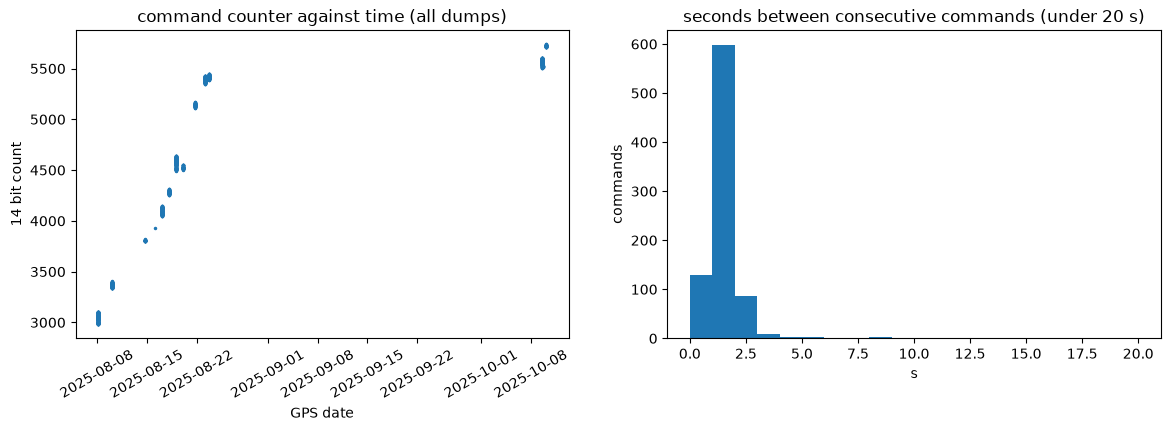

In [9]:
fig, (ax_count, ax_gap) = plt.subplots(1, 2, figsize=(14, 4))
all_times = np.array([t for items in by_file.values() for t, _ in items])
all_counts = np.array([c for items in by_file.values() for _, c in items])
order = np.argsort(all_times)
dates = np.array([GPS_EPOCH + timedelta(seconds=float(t) + GPS_MINUS_TICK) for t in all_times[order]])
ax_count.plot(dates, all_counts[order], ".", markersize=3)
ax_count.set(title="command counter against time (all dumps)", ylabel="14 bit count", xlabel="GPS date")
ax_count.tick_params(axis="x", rotation=30)

gaps = np.diff(np.sort(all_times))
ax_gap.hist(gaps[gaps < 20], bins=np.arange(0, 21))
ax_gap.set(title="seconds between consecutive commands (under 20 s)", xlabel="s", ylabel="commands")
plt.show()

Within a burst the counter grows by one per command. From the first dump (August 8) to the last (October 10) it goes
from 2 981 to 5 738 with one step back, between the dumps of August 19 and 20 (4 639, then 4 499 to 4 552). So the
counter climbs by about 2 800 over the 2 months while the dumps contain only 852 commands: most commands were sent
outside of the dumps. The climb is not even: 2 981 to 5 447 between August 8 and 23 (about 160 commands a day), then only
61 more until October 9 (5 508), so the commanding was much less busy in September. The commands come in bursts one to two seconds apart. See where the bursts are in a dump.

In [10]:
print(f"{'file':22s} bursts (size, seconds after the first APID 18 packet of the dump)")
for name in sorted(by_file):
    times = np.sort([t for t, _ in by_file[name]])
    bursts = np.split(times, np.nonzero(np.diff(times) > BURST_GAP)[0] + 1)
    start = span[name][0]
    print(f"{name:22s} " + ", ".join(f"({len(burst)}, {burst[0] - start:.0f})" for burst in bursts))

file                   bursts (size, seconds after the first APID 18 packet of the dump)
proba2_dump(1).cadu    (91, -18418), (3, -18031), (7, 94)
proba2_dump(10).cadu   (21, 6592)
proba2_dump(11).cadu   (1, 99), (68, 159)
proba2_dump(12).cadu   (35, 23), (89, 95)
proba2_dump(2).cadu    (58, 32732)
proba2_dump(3).cadu    (1, 85), (79, 144)
proba2_dump(4).cadu    (49, 2)
proba2_dump(5).cadu    (38, 18)
proba2_dump(6).cadu    (34, 5602), (96, 5702)
proba2_dump(7).cadu    (55, 49)
proba2_dump(8).cadu    (1, 5593), (94, 5644)
proba2_dump(9).cadu    (1, 89)
proba2_dump.cadu       (30, -7)


The commands of a dump are in one to three bursts of 20 to 100 commands (plus a few single ones) that last a minute or two. In 6 of the 13
dumps (6, 8, 10, 11, 12 and 3) they are late in the span of the APID 18 telemetry; in 4, 5 and 7 near its
start; and in dump 1 the biggest burst is 5 hours before it (and in dump 2 and the last one the span of the telemetry
is hours long, so the position means little). Commands can only reach the spacecraft in a ground contact, so these
are most likely uploads (a schedule, a table) during the contact in which the dump was recorded.

## 6. What we know so far

* APID 14 is PUS service 1 (telecommand verification): 1 731 usable reports of 24 bytes, 99.9 % with a valid CRC-16, 852
  telecommands (849 with both reports), each reported as accepted (subtype 1) and completed (subtype 7), about a millisecond apart.
* A report holds the tick and fraction (time of the report), and the request id of the command: packet id (always
  type 1, APID 14, secondary header) and a 14 bit sequence count, which grows by one per command within a burst and
  from 2 981 to 5 738 between August 8 and October 10 2025, with one step back.
* 852 commands in the 13 dumps, in bursts of 20 to 100 (plus a few single ones) that last a minute or two, probably uploads in the ground
  contact. The content of the commands is not in the downlink, so this log says *when* the spacecraft was commanded and not *what*.
* No LYRA data and nothing about the Sun or the attitude. It could still help with LYRA indirectly: a change of a LYRA
  setting (the integration time, for example) has to be commanded, and the list of the commands says when there was
  an upload.